In [1]:
!pip -q install pyspark==4.0.0

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 434.1/434.1 MB 2.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [2]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("Proyecto_BigData_Ventas") \
    .master("local[*]") \
    .getOrCreate()

print("PySpark funcionando correctamente")
print("Version de Spark:", spark.version)

PySpark funcionando correctamente
Version de Spark: 4.0.0


In [3]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os

ruta = "/content/drive/MyDrive/Proyecto_BigData"

print(os.listdir(ruta))

['customers.csv', 'discounts.csv', 'employees.csv', 'products.csv', 'stores.csv', 'transactions.csv', 'transacciones_parquet', 'modelo_random_forest_v3']


In [5]:
ruta_transacciones = ruta + "/transactions.csv"

transacciones = spark.read.csv(
    ruta_transacciones,
    header=True,
    inferSchema=False
)

print("Archivo cargado correctamente")

transacciones.printSchema()

transacciones.show(5, truncate=False)


Archivo cargado correctamente
root
 |-- Invoice ID: string (nullable = true)
 |-- Line: string (nullable = true)
 |-- Customer ID: string (nullable = true)
 |-- Product ID: string (nullable = true)
 |-- Size: string (nullable = true)
 |-- Color: string (nullable = true)
 |-- Unit Price: string (nullable = true)
 |-- Quantity: string (nullable = true)
 |-- Date: string (nullable = true)
 |-- Discount: string (nullable = true)
 |-- Line Total: string (nullable = true)
 |-- Store ID: string (nullable = true)
 |-- Employee ID: string (nullable = true)
 |-- Currency: string (nullable = true)
 |-- Currency Symbol: string (nullable = true)
 |-- SKU: string (nullable = true)
 |-- Transaction Type: string (nullable = true)
 |-- Payment Method: string (nullable = true)
 |-- Invoice Total: string (nullable = true)

+-------------------+----+-----------+----------+----+-------+----------+--------+-------------------+--------+----------+--------+-----------+--------+---------------+----------------

In [6]:
total_registros = transacciones.count()

print("Total de registros:", total_registros)
print("Total de columnas:", len(transacciones.columns))

Total de registros: 6416827
Total de columnas: 19


In [7]:
from pyspark.sql import functions as F

columnas_revisar = [
    "Invoice ID",
    "Product ID",
    "Unit Price",
    "Quantity",
    "Date",
    "Line Total"
]

resultado = transacciones.select([
    F.sum(
        F.when(
            F.col(f"`{columna}`").isNull() |
            (F.trim(F.col(f"`{columna}`")) == ""),
            1
        ).otherwise(0)
    ).alias(columna)
    for columna in columnas_revisar
])

resultado.show(truncate=False)

+----------+----------+----------+--------+----+----------+
|Invoice ID|Product ID|Unit Price|Quantity|Date|Line Total|
+----------+----------+----------+--------+----+----------+
|0         |0         |0         |0       |0   |0         |
+----------+----------+----------+--------+----+----------+



In [8]:
from pyspark.sql import functions as F

transacciones_limpias = (
    transacciones
    .withColumn("Unit Price", F.expr("try_cast(`Unit Price` AS DOUBLE)"))
    .withColumn("Quantity", F.expr("try_cast(`Quantity` AS INT)"))
    .withColumn("Discount", F.expr("try_cast(`Discount` AS DOUBLE)"))
    .withColumn("Line Total", F.expr("try_cast(`Line Total` AS DOUBLE)"))
    .withColumn("Invoice Total", F.expr("try_cast(`Invoice Total` AS DOUBLE)"))
    .withColumn("Date", F.expr("try_cast(`Date` AS TIMESTAMP)"))
)

print("Conversion de datos realizada")

transacciones_limpias.printSchema()

Conversion de datos realizada
root
 |-- Invoice ID: string (nullable = true)
 |-- Line: string (nullable = true)
 |-- Customer ID: string (nullable = true)
 |-- Product ID: string (nullable = true)
 |-- Size: string (nullable = true)
 |-- Color: string (nullable = true)
 |-- Unit Price: double (nullable = true)
 |-- Quantity: integer (nullable = true)
 |-- Date: timestamp (nullable = true)
 |-- Discount: double (nullable = true)
 |-- Line Total: double (nullable = true)
 |-- Store ID: string (nullable = true)
 |-- Employee ID: string (nullable = true)
 |-- Currency: string (nullable = true)
 |-- Currency Symbol: string (nullable = true)
 |-- SKU: string (nullable = true)
 |-- Transaction Type: string (nullable = true)
 |-- Payment Method: string (nullable = true)
 |-- Invoice Total: double (nullable = true)



In [9]:
columnas_numericas = [
    "Unit Price",
    "Quantity",
    "Discount",
    "Line Total",
    "Invoice Total",
    "Date"
]

resultado_conversion = transacciones_limpias.select([
    F.count(
        F.when(F.col(f"`{columna}`").isNull(), 1)
    ).alias(columna)
    for columna in columnas_numericas
])

print("Valores nulos despues de la conversion:")
resultado_conversion.show(truncate=False)

Valores nulos despues de la conversion:
+----------+--------+--------+----------+-------------+----+
|Unit Price|Quantity|Discount|Line Total|Invoice Total|Date|
+----------+--------+--------+----------+-------------+----+
|0         |0       |0       |0         |0            |0   |
+----------+--------+--------+----------+-------------+----+



In [10]:
transacciones_procesadas = (
    transacciones_limpias
    .withColumnRenamed("Date", "Fecha")
    .withColumn("Anio", F.year(F.col("Fecha")))
    .withColumn("Mes", F.month(F.col("Fecha")))
)

print("Columnas creadas y renombradas correctamente")

transacciones_procesadas.select(
    "Fecha", "Anio", "Mes"
).show(5)

Columnas creadas y renombradas correctamente
+-------------------+----+---+
|              Fecha|Anio|Mes|
+-------------------+----+---+
|2023-01-01 15:42:00|2023|  1|
|2023-01-01 15:42:00|2023|  1|
|2023-01-01 15:42:00|2023|  1|
|2023-01-01 20:04:00|2023|  1|
|2023-01-01 20:04:00|2023|  1|
+-------------------+----+---+
only showing top 5 rows


In [11]:
ruta_parquet = "/content/transacciones_parquet"

(
    transacciones_procesadas
    .repartition(8, "Anio", "Mes")
    .write
    .mode("overwrite")
    .partitionBy("Anio", "Mes")
    .parquet(ruta_parquet)
)

print("Archivos Parquet creados correctamente")

Archivos Parquet creados correctamente


In [12]:
import os

print("Carpetas creadas:")
print(os.listdir(ruta_parquet))

datos_parquet = spark.read.parquet(ruta_parquet)

print("Total de registros:", datos_parquet.count())
print("Total de columnas:", len(datos_parquet.columns))

Carpetas creadas:
['._SUCCESS.crc', 'Anio=2024', 'Anio=2025', 'Anio=2023', '_SUCCESS']
Total de registros: 6416827
Total de columnas: 21


In [13]:
import shutil

ruta_respaldo = ruta + "/transacciones_parquet"

shutil.copytree(
    ruta_parquet,
    ruta_respaldo,
    dirs_exist_ok=True
)

print("Respaldo completado en Google Drive")

Respaldo completado en Google Drive


In [14]:
from pyspark.sql import functions as F

resumen_ventas = datos_parquet.agg(
    F.count("*").alias("Total de Registros"),
    F.countDistinct("Invoice ID").alias("Total de Facturas"),
    F.sum("Quantity").alias("Unidades Registradas"),
    F.round(F.sum("Line Total"), 2).alias("Importe Total"),
    F.round(F.avg("Line Total"), 2).alias("Promedio por Linea")
)

print("RESUMEN GENERAL DE VENTAS")
resumen_ventas.show(truncate=False)

RESUMEN GENERAL DE VENTAS
+------------------+-----------------+--------------------+--------------+------------------+
|Total de Registros|Total de Facturas|Unidades Registradas|Importe Total |Promedio por Linea|
+------------------+-----------------+--------------------+--------------+------------------+
|6416827           |4540404          |7060071             |7.3274487499E8|114.19            |
+------------------+-----------------+--------------------+--------------+------------------+



In [15]:
ventas_por_anio = (
    datos_parquet
    .groupBy("Anio")
    .agg(
        F.count("*").alias("Cantidad de Registros"),
        F.round(F.sum("Line Total"), 2).alias("Importe Registrado")
    )
    .select(
        F.col("Anio").alias("Año"),
        F.col("Cantidad de Registros"),
        F.col("Importe Registrado")
    )
    .orderBy("Año")
)

print("REGISTROS E IMPORTES POR AÑO")
ventas_por_anio.show(truncate=False)

REGISTROS E IMPORTES POR AÑO
+----+---------------------+------------------+
|Año |Cantidad de Registros|Importe Registrado|
+----+---------------------+------------------+
|2023|2809513              |3.0495598103E8    |
|2024|3150961              |3.8290712876E8    |
|2025|456353               |4.48817652E7      |
+----+---------------------+------------------+



In [16]:
print("MONEDAS UTILIZADAS")

datos_parquet.groupBy("Currency") \
    .count() \
    .select(
        F.col("Currency").alias("Moneda"),
        F.col("count").alias("Cantidad de Registros")
    ) \
    .orderBy(F.desc("Cantidad de Registros")) \
    .show(truncate=False)


print("TIPOS DE TRANSACCION")

datos_parquet.groupBy("Transaction Type") \
    .count() \
    .select(
        F.when(F.col("Transaction Type") == "Sale", "Venta")
         .when(F.col("Transaction Type") == "Return", "Devolución")
         .otherwise(F.col("Transaction Type"))
         .alias("Tipo de Transacción"),
        F.col("count").alias("Cantidad de Registros")
    ) \
    .orderBy(F.desc("Cantidad de Registros")) \
    .show(truncate=False)


print("RANGO DE FECHAS")

datos_parquet.select(
    F.min("Fecha").alias("Primera Fecha"),
    F.max("Fecha").alias("Última Fecha")
).show(truncate=False)

MONEDAS UTILIZADAS
+------+---------------------+
|Moneda|Cantidad de Registros|
+------+---------------------+
|EUR   |2549397              |
|USD   |1687764              |
|CNY   |1553438              |
|GBP   |626228               |
+------+---------------------+

TIPOS DE TRANSACCION
+-------------------+---------------------+
|Tipo de Transacción|Cantidad de Registros|
+-------------------+---------------------+
|Venta              |6077200              |
|Devolución         |339627               |
+-------------------+---------------------+

RANGO DE FECHAS
+-------------------+-------------------+
|Primera Fecha      |Última Fecha       |
+-------------------+-------------------+
|2023-01-01 00:00:00|2025-03-18 20:59:00|
+-------------------+-------------------+



In [17]:
ventas = datos_parquet.filter(
    F.col("Transaction Type") == "Sale"
)

devoluciones = datos_parquet.filter(
    F.col("Transaction Type") == "Return"
)

print("REGISTROS DE VENTAS:", ventas.count())
print("REGISTROS DE DEVOLUCIONES:", devoluciones.count())


print("EJEMPLO DE VENTAS")

ventas.select(
    F.col("Invoice ID").alias("ID de Factura"),
    F.col("Fecha"),
    F.col("Quantity").alias("Cantidad"),
    F.col("Line Total").alias("Total de Línea"),
    F.col("Currency").alias("Moneda")
).show(5, truncate=False)


print("EJEMPLO DE DEVOLUCIONES")

devoluciones.select(
    F.col("Invoice ID").alias("ID de Factura"),
    F.col("Fecha"),
    F.col("Quantity").alias("Cantidad"),
    F.col("Line Total").alias("Total de Línea"),
    F.col("Currency").alias("Moneda")
).show(5, truncate=False)

REGISTROS DE VENTAS: 6077200
REGISTROS DE DEVOLUCIONES: 339627
EJEMPLO DE VENTAS
+-------------------+-------------------+--------+--------------+------+
|ID de Factura      |Fecha              |Cantidad|Total de Línea|Moneda|
+-------------------+-------------------+--------+--------------+------+
|INV-US-001-03815458|2024-12-01 20:18:00|1       |59.5          |USD   |
|INV-CN-009-05095076|2024-12-01 18:41:00|1       |430.0         |CNY   |
|INV-US-001-03815458|2024-12-01 20:18:00|3       |204.0         |USD   |
|INV-CN-009-05095077|2024-12-01 09:41:00|1       |746.5         |CNY   |
|INV-US-001-03815458|2024-12-01 20:18:00|1       |16.0          |USD   |
+-------------------+-------------------+--------+--------------+------+
only showing top 5 rows
EJEMPLO DE DEVOLUCIONES
+-------------------+-------------------+--------+--------------+------+
|ID de Factura      |Fecha              |Cantidad|Total de Línea|Moneda|
+-------------------+-------------------+--------+--------------+---

In [18]:
resumen_monedas = (
    datos_parquet
    .groupBy("Currency")
    .agg(
        F.round(
            F.sum(
                F.when(
                    F.col("Transaction Type") == "Sale",
                    F.col("Line Total")
                ).otherwise(0)
            ), 2
        ).alias("Ventas_Brutas"),

        F.round(
            F.sum(
                F.when(
                    F.col("Transaction Type") == "Return",
                    F.col("Line Total")
                ).otherwise(0)
            ), 2
        ).alias("Devoluciones"),

        F.round(
            F.sum("Line Total"), 2
        ).alias("Ventas_Netas")
    )
    .orderBy("Currency")
)

print("RESUMEN DE VENTAS POR MONEDA")

resumen_monedas.select(
    F.col("Currency").alias("Moneda"),
    F.col("Ventas_Brutas").alias("Ventas Brutas"),
    F.col("Devoluciones").alias("Devoluciones"),
    F.col("Ventas_Netas").alias("Ventas Netas")
).show(truncate=False)

RESUMEN DE VENTAS POR MONEDA
+------+--------------+--------------+--------------+
|Moneda|Ventas Brutas |Devoluciones  |Ventas Netas  |
+------+--------------+--------------+--------------+
|CNY   |5.7030742615E8|-3.176816974E7|5.3853925641E8|
|EUR   |1.0785486874E8|-6072116.31   |1.0178275243E8|
|GBP   |1.8434022E7   |-1034667.55   |1.739935445E7 |
|USD   |7.946420573E7 |-4440694.03   |7.50235117E7  |
+------+--------------+--------------+--------------+



In [19]:
ventas_anuales = (
    datos_parquet
    .groupBy("Anio", "Currency")
    .agg(
        F.round(
            F.sum("Line Total"), 2
        ).alias("Ventas_Netas")
    )
    .orderBy("Anio", "Currency")
)

print("VENTAS NETAS POR AÑO Y MONEDA")

ventas_anuales.select(
    F.col("Anio").alias("Año"),
    F.col("Currency").alias("Moneda"),
    F.col("Ventas_Netas").alias("Ventas Netas")
).show(20, truncate=False)

VENTAS NETAS POR AÑO Y MONEDA
+----+------+--------------+
|Año |Moneda|Ventas Netas  |
+----+------+--------------+
|2023|CNY   |2.1746469498E8|
|2023|EUR   |4.597212171E7 |
|2023|GBP   |8089009.06    |
|2023|USD   |3.343015528E7 |
|2024|CNY   |2.8992650261E8|
|2024|EUR   |4.93158255E7  |
|2024|GBP   |8550709.15    |
|2024|USD   |3.51140915E7  |
|2025|CNY   |3.114805882E7 |
|2025|EUR   |6494805.22    |
|2025|GBP   |759636.24     |
|2025|USD   |6479264.92    |
+----+------+--------------+



In [20]:
from pyspark.sql import functions as F

print("RESUMEN DE VENTAS POR MONEDA")

resumen_monedas.select(
    F.col("Currency").alias("Moneda"),

    F.format_number(
        F.col("Ventas_Brutas"), 2
    ).alias("Ventas Brutas"),

    F.format_number(
        F.col("Devoluciones"), 2
    ).alias("Devoluciones"),

    F.format_number(
        F.col("Ventas_Netas"), 2
    ).alias("Ventas Netas")
).show(truncate=False)


print("VENTAS NETAS POR AÑO Y MONEDA")

ventas_anuales.select(
    F.col("Anio").alias("Año"),
    F.col("Currency").alias("Moneda"),

    F.format_number(
        F.col("Ventas_Netas"), 2
    ).alias("Ventas Netas")
).show(20, truncate=False)

RESUMEN DE VENTAS POR MONEDA
+------+--------------+--------------+--------------+
|Moneda|Ventas Brutas |Devoluciones  |Ventas Netas  |
+------+--------------+--------------+--------------+
|CNY   |570,307,426.15|-31,768,169.74|538,539,256.41|
|EUR   |107,854,868.74|-6,072,116.31 |101,782,752.43|
|GBP   |18,434,022.00 |-1,034,667.55 |17,399,354.45 |
|USD   |79,464,205.73 |-4,440,694.03 |75,023,511.70 |
+------+--------------+--------------+--------------+

VENTAS NETAS POR AÑO Y MONEDA
+----+------+--------------+
|Año |Moneda|Ventas Netas  |
+----+------+--------------+
|2023|CNY   |217,464,694.98|
|2023|EUR   |45,972,121.71 |
|2023|GBP   |8,089,009.06  |
|2023|USD   |33,430,155.28 |
|2024|CNY   |289,926,502.61|
|2024|EUR   |49,315,825.50 |
|2024|GBP   |8,550,709.15  |
|2024|USD   |35,114,091.50 |
|2025|CNY   |31,148,058.82 |
|2025|EUR   |6,494,805.22  |
|2025|GBP   |759,636.24    |
|2025|USD   |6,479,264.92  |
+----+------+--------------+



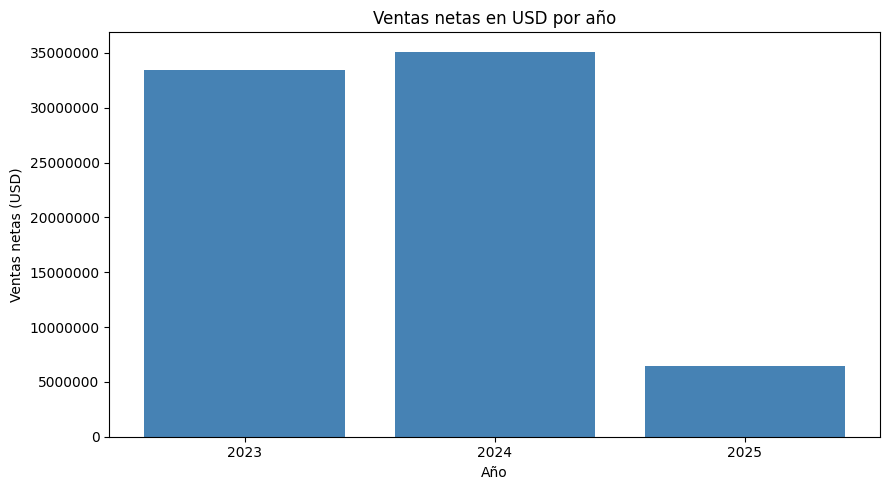

In [21]:
import matplotlib.pyplot as plt

ventas_usd = (
    ventas_anuales
    .filter(F.col("Currency") == "USD")
    .orderBy("Anio")
    .toPandas()
)

plt.figure(figsize=(9, 5))

plt.bar(
    ventas_usd["Anio"].astype(str),
    ventas_usd["Ventas_Netas"],
    color="steelblue"
)

plt.title("Ventas netas en USD por año")
plt.xlabel("Año")
plt.ylabel("Ventas netas (USD)")

plt.ticklabel_format(
    style="plain",
    axis="y"
)

plt.tight_layout()
plt.show()

In [22]:
ventas_mensuales = (
    datos_parquet
    .filter(F.col("Currency") == "USD")
    .groupBy("Anio", "Mes")
    .agg(
        F.round(
            F.sum("Line Total"), 2
        ).alias("Ventas_Netas")
    )
    .orderBy("Anio", "Mes")
)

print("VENTAS MENSUALES EN USD")

ventas_mensuales.select(
    F.col("Anio").alias("Año"),
    F.col("Mes"),
    F.format_number(
        F.col("Ventas_Netas"), 2
    ).alias("Ventas Netas (USD)")
).show(30, truncate=False)

VENTAS MENSUALES EN USD
+----+---+------------------+
|Año |Mes|Ventas Netas (USD)|
+----+---+------------------+
|2023|1  |1,671,839.80      |
|2023|2  |1,243,827.80      |
|2023|3  |3,088,239.42      |
|2023|4  |2,797,403.97      |
|2023|5  |2,578,223.51      |
|2023|6  |1,699,770.00      |
|2023|7  |2,078,775.50      |
|2023|8  |1,622,888.00      |
|2023|9  |3,831,854.21      |
|2023|10 |3,474,305.12      |
|2023|11 |3,018,398.60      |
|2023|12 |6,324,629.35      |
|2024|1  |1,623,398.95      |
|2024|2  |1,454,759.80      |
|2024|3  |3,644,353.91      |
|2024|4  |2,619,980.68      |
|2024|5  |2,375,938.71      |
|2024|6  |2,001,023.51      |
|2024|7  |1,873,770.50      |
|2024|8  |1,916,397.50      |
|2024|9  |4,334,816.99      |
|2024|10 |3,986,233.20      |
|2024|11 |2,989,867.90      |
|2024|12 |6,293,549.85      |
|2025|1  |2,192,318.55      |
|2025|2  |1,865,538.10      |
|2025|3  |2,421,408.27      |
+----+---+------------------+



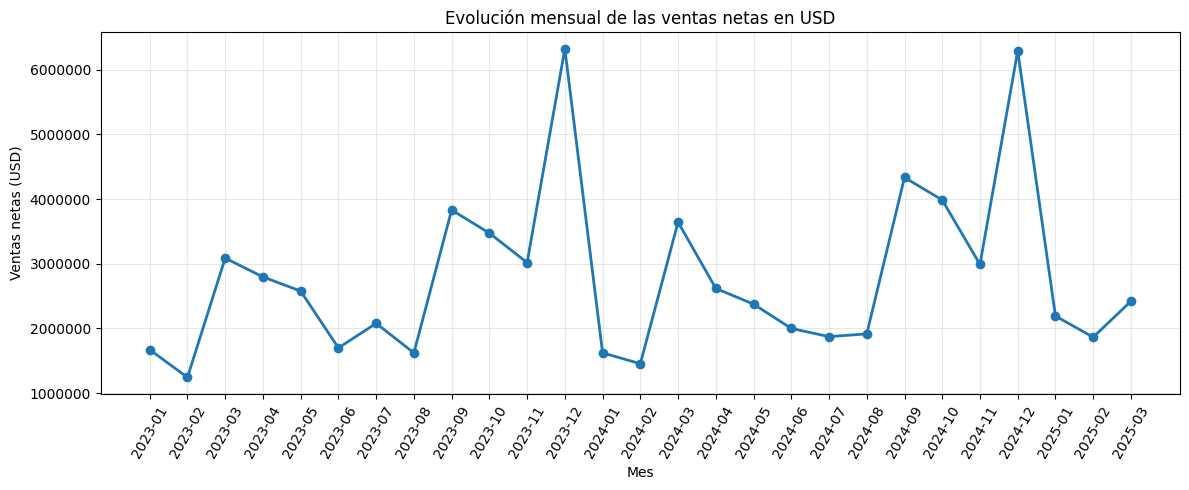

In [23]:
ventas_mensuales_pd = ventas_mensuales.toPandas()

ventas_mensuales_pd["Periodo"] = (
    ventas_mensuales_pd["Anio"].astype(str)
    + "-"
    + ventas_mensuales_pd["Mes"].astype(str).str.zfill(2)
)

plt.figure(figsize=(12, 5))

plt.plot(
    ventas_mensuales_pd["Periodo"],
    ventas_mensuales_pd["Ventas_Netas"],
    marker="o",
    linewidth=2
)

plt.title("Evolución mensual de las ventas netas en USD")
plt.xlabel("Mes")
plt.ylabel("Ventas netas (USD)")

plt.xticks(rotation=60)
plt.ticklabel_format(style="plain", axis="y")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [24]:
productos_vendidos = (
    ventas
    .groupBy("Product ID")
    .agg(
        F.sum("Quantity").alias("Unidades_Vendidas"),
        F.count("*").alias("Registros_de_Venta")
    )
    .orderBy(F.desc("Unidades_Vendidas"))
)

print("LOS 10 PRODUCTOS MAS VENDIDOS")

productos_vendidos.select(
    F.col("Product ID").alias("ID del Producto"),
    F.col("Unidades_Vendidas").alias("Unidades Vendidas"),
    F.col("Registros_de_Venta").alias("Registros de Venta")
).show(10, truncate=False)

LOS 10 PRODUCTOS MAS VENDIDOS
+---------------+-----------------+------------------+
|ID del Producto|Unidades Vendidas|Registros de Venta|
+---------------+-----------------+------------------+
|12235          |1031             |918               |
|14729          |1023             |935               |
|14458          |1019             |898               |
|12417          |1011             |903               |
|14134          |1009             |898               |
|12391          |1007             |947               |
|13288          |1003             |885               |
|12638          |1001             |893               |
|14443          |1001             |896               |
|12002          |1000             |892               |
+---------------+-----------------+------------------+
only showing top 10 rows


In [25]:
actividad_tiendas = (
    ventas
    .groupBy("Store ID")
    .agg(
        F.count("*").alias("Registros_de_Venta"),
        F.sum("Quantity").alias("Unidades_Vendidas")
    )
    .orderBy(F.desc("Registros_de_Venta"))
)

print("LAS 10 TIENDAS CON MAYOR ACTIVIDAD")

actividad_tiendas.select(
    F.col("Store ID").alias("ID de la Tienda"),
    F.col("Registros_de_Venta").alias("Registros de Venta"),
    F.col("Unidades_Vendidas").alias("Unidades Vendidas")
).show(10, truncate=False)

LAS 10 TIENDAS CON MAYOR ACTIVIDAD
+---------------+------------------+-----------------+
|ID de la Tienda|Registros de Venta|Unidades Vendidas|
+---------------+------------------+-----------------+
|1              |452461            |497826           |
|2              |432035            |474915           |
|6              |363203            |399454           |
|8              |350984            |386172           |
|9              |298322            |328097           |
|4              |294760            |324470           |
|7              |270676            |297646           |
|11             |258449            |284338           |
|3              |226012            |248428           |
|5              |193195            |212719           |
+---------------+------------------+-----------------+
only showing top 10 rows


In [26]:
ruta_productos = ruta + "/products.csv"

productos = spark.read.csv(
    ruta_productos,
    header=True,
    inferSchema=False
)

print("ARCHIVO DE PRODUCTOS CARGADO CORRECTAMENTE")

productos.printSchema()

print("PRIMEROS 5 PRODUCTOS")
productos.show(5, truncate=False)

print("TOTAL DE PRODUCTOS:", productos.count)

ARCHIVO DE PRODUCTOS CARGADO CORRECTAMENTE
root
 |-- Product ID: string (nullable = true)
 |-- Category: string (nullable = true)
 |-- Sub Category: string (nullable = true)
 |-- Description PT: string (nullable = true)
 |-- Description DE: string (nullable = true)
 |-- Description FR: string (nullable = true)
 |-- Description ES: string (nullable = true)
 |-- Description EN: string (nullable = true)
 |-- Description ZH: string (nullable = true)
 |-- Color: string (nullable = true)
 |-- Sizes: string (nullable = true)
 |-- Production Cost: string (nullable = true)

PRIMEROS 5 PRODUCTOS
+----------+--------+---------------------+---------------------------------+---------------------------------+-------------------------------------+----------------------------------+---------------------------------+------------------------+-----+--------+---------------+
|Product ID|Category|Sub Category         |Description PT                   |Description DE                   |Description FR       

In [27]:
print("TOTAL DE PRODUCTOS:", productos.count())

productos_info = productos.select(
    F.col("Product ID"),
    F.col("Category").alias("Categoria"),
    F.col("Sub Category").alias("Subcategoria"),
    F.col("Description ES").alias("Descripcion"),
)

ventas_productos = ventas.join(
    productos_info,
    on="Product ID",
    how="left"
)

print("REGISTROS DE VENTA ORIGINALES:", ventas.count())
print("REGISTROS DESPUES DE LA UNION:", ventas_productos.count())

print("EJEMPLO DE PRODUCTOS RELACIONADOS")

ventas_productos.select(
    F.col("Product ID").alias("ID del Producto"),
    F.col("Descripcion").alias("Descripción"),
    F.col("Categoria").alias("Categoría"),
    F.col("Quantity").alias("Cantidad"),
    F.col("Line Total").alias("Total de Línea")
).show(10, truncate=False)

TOTAL DE PRODUCTOS: 17940
REGISTROS DE VENTA ORIGINALES: 6077200
REGISTROS DESPUES DE LA UNION: 6077200
EJEMPLO DE PRODUCTOS RELACIONADOS
+---------------+---------------------------------------------------------------+---------+--------+--------------+
|ID del Producto|Descripción                                                    |Categoría|Cantidad|Total de Línea|
+---------------+---------------------------------------------------------------+---------+--------+--------------+
|12623          |Ingresos De Robo Ejecutivo Con Volantes                        |Masculine|1       |59.5          |
|12784          |Pantalones Cortos De Fútbol Masculino Con Detalles De Contraste|Masculine|1       |430.0         |
|13472          |Blusa Con Escote Cuadrado                                      |Feminine |3       |204.0         |
|12455          |Nylon Nylon Sports Impreso                                     |Feminine |1       |746.5         |
|13488          |Llavero Para Hombres Con Diseño P

In [28]:
productos_mas_vendidos = (
    ventas_productos
    .groupBy("Product ID", "Descripcion")
    .agg(
        F.sum("Quantity").alias("Unidades_Vendidas"),
        F.count("*").alias("Registros_de_Venta")
    )
    .orderBy(F.desc("Unidades_Vendidas"))
)

print("LOS 10 PRODUCTOS MAS VENDIDOS")

productos_mas_vendidos.select(
    F.col("Product ID").alias("ID del Producto"),
    F.col("Descripcion").alias("Descripción"),
    F.col("Unidades_Vendidas").alias("Unidades Vendidas"),
    F.col("Registros_de_Venta").alias("Registros de Venta")
).show(10, truncate=False)

LOS 10 PRODUCTOS MAS VENDIDOS
+---------------+--------------------------------------------------------+-----------------+------------------+
|ID del Producto|Descripción                                             |Unidades Vendidas|Registros de Venta|
+---------------+--------------------------------------------------------+-----------------+------------------+
|12235          |Camisa Masculina De Manga Curta Com Bolsos              |1031             |918               |
|14729          |Turquesa Clásica Con Arco                               |1023             |935               |
|14458          |Jacquard Blanco Retro Con Flecos                        |1019             |898               |
|12417          |Polo De Menos Con Detalles De Rayas                     |1011             |903               |
|14134          |Jeans Masculino De Cintura Média Com Barra Reta         |1009             |898               |
|12391          |Camisa Tricolina Para Hombres Con Cuello Alto           |

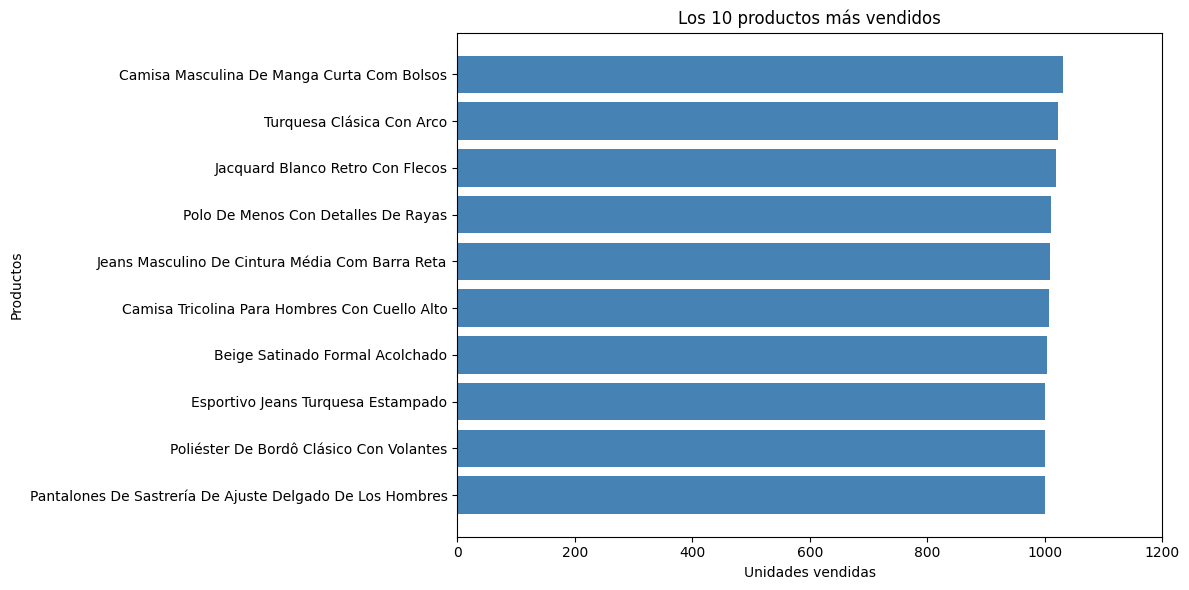

In [29]:
top_productos = productos_mas_vendidos.limit(10).toPandas()

top_productos = top_productos.sort_values(
    "Unidades_Vendidas",
    ascending=True
)

plt.figure(figsize=(12, 6))

plt.barh(
    top_productos["Descripcion"],
    top_productos["Unidades_Vendidas"],
    color="steelblue"
)

plt.title("Los 10 productos más vendidos")
plt.xlabel("Unidades vendidas")
plt.ylabel("Productos")

plt.xlim(0, 1200)

plt.tight_layout()
plt.show()

In [30]:
ruta_tiendas = ruta + "/stores.csv"

tiendas = spark.read.csv(
    ruta_tiendas,
    header=True,
    inferSchema=False
)

print("ARCHIVO DE TIENDAS CARGADO CORRECTAMENTE")

tiendas.printSchema()

print("PRIMERAS 5 TIENDAS")
tiendas.show(5, truncate=False)

print("TOTAL DE TIENDAS:", tiendas.count())

ARCHIVO DE TIENDAS CARGADO CORRECTAMENTE
root
 |-- Store ID: string (nullable = true)
 |-- Country: string (nullable = true)
 |-- City: string (nullable = true)
 |-- Store Name: string (nullable = true)
 |-- Number of Employees: string (nullable = true)
 |-- ZIP Code: string (nullable = true)
 |-- Latitude: string (nullable = true)
 |-- Longitude: string (nullable = true)

PRIMERAS 5 TIENDAS
+--------+-------------+-----------+-----------------+-------------------+--------+--------+---------+
|Store ID|Country      |City       |Store Name       |Number of Employees|ZIP Code|Latitude|Longitude|
+--------+-------------+-----------+-----------------+-------------------+--------+--------+---------+
|1       |United States|New York   |Store New York   |10                 |10001   |40.7128 |-74.006  |
|2       |United States|Los Angeles|Store Los Angeles|8                  |90001   |34.0522 |-118.2437|
|3       |United States|Chicago    |Store Chicago    |9                  |60601   |41.8781

In [31]:
tiendas_info = tiendas.select(
    F.col("Store ID"),
    F.col("Country").alias("Pais"),
    F.col("City").alias("Ciudad"),
    F.col("Store Name").alias("Nombre_Tienda"),
    F.col("Number of Employees").alias("Empleados")
)

ventas_tiendas = ventas.join(
    tiendas_info,
    on="Store ID",
    how="left"
)

print("REGISTROS DE VENTA ORIGINALES:", ventas.count())

print("REGISTROS DESPUES DE LA UNION:", ventas_tiendas.count())

print("EJEMPLO DE TIENDAS RELACIONADAS")

ventas_tiendas.select(
    F.col("Store ID").alias("ID de Tienda"),
    F.col("Nombre_Tienda").alias("Nombre de Tienda"),
    F.col("Pais").alias("País"),
    F.col("Ciudad"),
    F.col("Quantity").alias("Cantidad"),
    F.col("Currency").alias("Moneda")
).show(10, truncate=False)

REGISTROS DE VENTA ORIGINALES: 6077200
REGISTROS DESPUES DE LA UNION: 6077200
EJEMPLO DE TIENDAS RELACIONADAS
+------------+----------------+-------------+--------+--------+------+
|ID de Tienda|Nombre de Tienda|País         |Ciudad  |Cantidad|Moneda|
+------------+----------------+-------------+--------+--------+------+
|1           |Store New York  |United States|New York|1       |USD   |
|9           |Store 深圳      |中国         |深圳    |1       |CNY   |
|1           |Store New York  |United States|New York|3       |USD   |
|9           |Store 深圳      |中国         |深圳    |1       |CNY   |
|1           |Store New York  |United States|New York|1       |USD   |
|9           |Store 深圳      |中国         |深圳    |1       |CNY   |
|1           |Store New York  |United States|New York|1       |USD   |
|9           |Store 深圳      |中国         |深圳    |1       |CNY   |
|1           |Store New York  |United States|New York|1       |USD   |
|9           |Store 深圳      |中国         |深圳    |1       |CNY  

In [32]:
tiendas_mas_activas = (
    ventas_tiendas
    .groupBy(
        "Store ID",
        "Nombre_Tienda",
        "Pais",
        "Ciudad"
    )
    .agg(
        F.count("*").alias("Registros_de_Venta"),
        F.sum("Quantity").alias("Unidades_Vendidas")
    )
    .orderBy(F.desc("Registros_de_Venta"))
)

print("LAS 10 TIENDAS CON MAYOR ACTIVIDAD")

tiendas_mas_activas.select(
    F.col("Store ID").alias("ID de Tienda"),
    F.col("Nombre_Tienda").alias("Nombre de Tienda"),
    F.col("Pais").alias("País"),
    F.col("Ciudad"),
    F.col("Registros_de_Venta").alias("Registros de Venta"),
    F.col("Unidades_Vendidas").alias("Unidades Vendidas")
).show(10, truncate=False)

LAS 10 TIENDAS CON MAYOR ACTIVIDAD
+------------+-----------------+-------------+-----------+------------------+-----------------+
|ID de Tienda|Nombre de Tienda |País         |Ciudad     |Registros de Venta|Unidades Vendidas|
+------------+-----------------+-------------+-----------+------------------+-----------------+
|1           |Store New York   |United States|New York   |452461            |497826           |
|2           |Store Los Angeles|United States|Los Angeles|432035            |474915           |
|6           |Store 上海       |中国         |上海       |363203            |399454           |
|8           |Store 广州       |中国         |广州       |350984            |386172           |
|9           |Store 深圳       |中国         |深圳       |298322            |328097           |
|4           |Store Houston    |United States|Houston    |294760            |324470           |
|7           |Store 北京       |中国         |北京       |270676            |297646           |
|11          |Store Berlin   

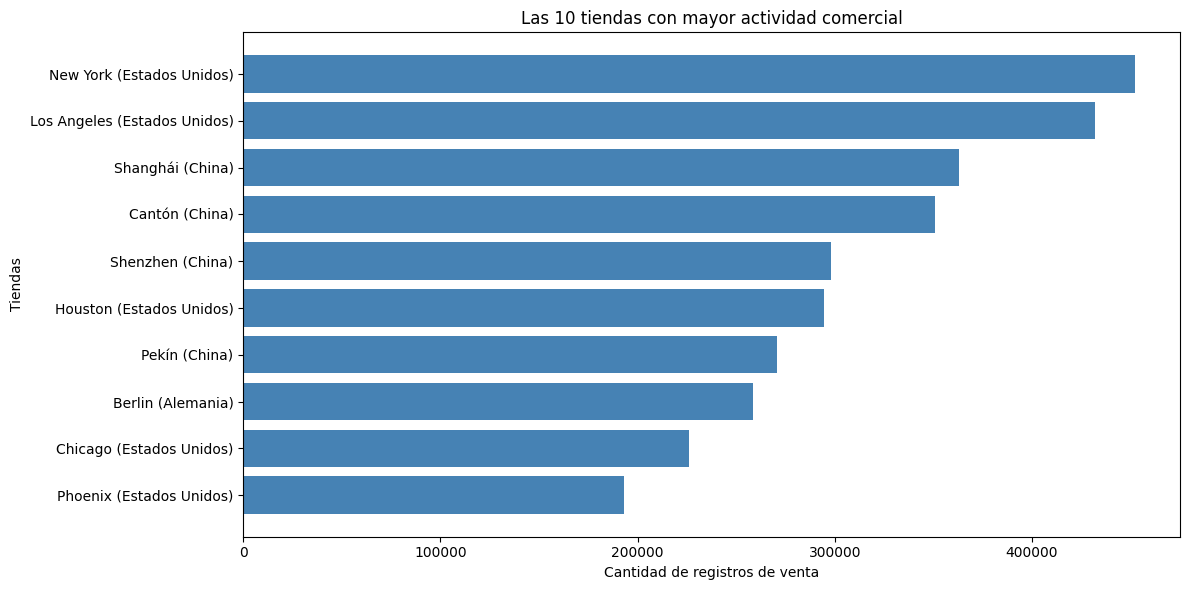

In [33]:
top_tiendas = tiendas_mas_activas.limit(10).toPandas()

nombres_ciudades = {
    "上海": "Shanghái",
    "广州": "Cantón",
    "深圳": "Shenzhen",
    "北京": "Pekín"
}

nombres_paises = {
    "中国": "China",
    "United States": "Estados Unidos",
    "Deutschland": "Alemania"
}

top_tiendas["Ciudad_ES"] = (
    top_tiendas["Ciudad"]
    .replace(nombres_ciudades)
)

top_tiendas["Pais_ES"] = (
    top_tiendas["Pais"]
    .replace(nombres_paises)
)

top_tiendas["Tienda"] = (
    top_tiendas["Ciudad_ES"]
    + " ("
    + top_tiendas["Pais_ES"]
    + ")"
)

top_tiendas = top_tiendas.sort_values(
    "Registros_de_Venta",
    ascending=True
)

plt.figure(figsize=(12, 6))

plt.barh(
    top_tiendas["Tienda"],
    top_tiendas["Registros_de_Venta"],
    color="steelblue"
)

plt.title("Las 10 tiendas con mayor actividad comercial")
plt.xlabel("Cantidad de registros de venta")
plt.ylabel("Tiendas")

plt.tight_layout()
plt.show()

In [34]:
ventas_categorias = (
    ventas_productos
    .groupBy("Categoria")
    .agg(
        F.sum("Quantity").alias("Unidades_Vendidas"),
        F.count("*").alias("Registros_de_Venta")
    )
    .orderBy(F.desc("Unidades_Vendidas"))
)

print("VENTAS POR CATEGORIA")

ventas_categorias.select(
    F.col("Categoria").alias("Categoría"),
    F.col("Unidades_Vendidas").alias("Unidades Vendidas"),
    F.col("Registros_de_Venta").alias("Registros de Venta")
).show(truncate=False)

VENTAS POR CATEGORIA
+---------+-----------------+------------------+
|Categoría|Unidades Vendidas|Registros de Venta|
+---------+-----------------+------------------+
|Feminine |3215951          |2923362           |
|Masculine|2644708          |2403153           |
|Children |825465           |750685            |
+---------+-----------------+------------------+



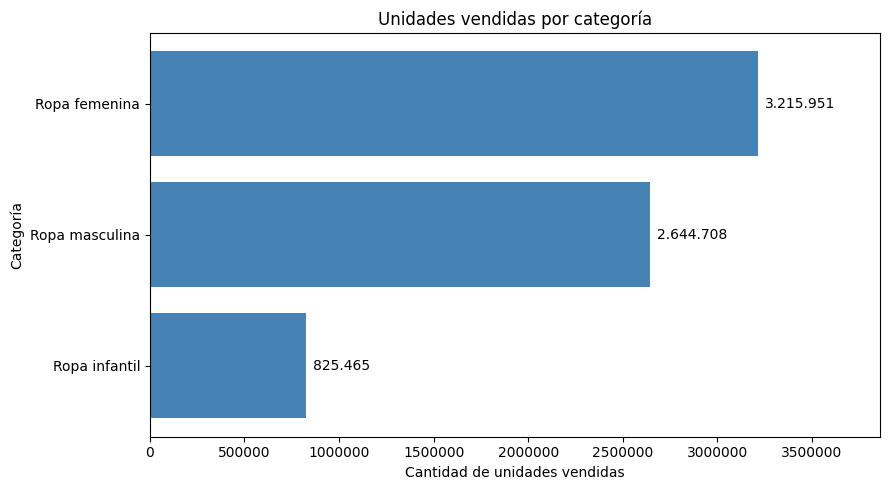

In [35]:
categorias_grafico = ventas_categorias.toPandas()

traducciones = {
    "Feminine": "Ropa femenina",
    "Masculine": "Ropa masculina",
    "Children": "Ropa infantil"
}

categorias_grafico["Categoria_ES"] = (
    categorias_grafico["Categoria"].replace(traducciones)
)

categorias_grafico = categorias_grafico.sort_values(
    "Unidades_Vendidas",
    ascending=True
)

plt.figure(figsize=(9, 5))

barras = plt.barh(
    categorias_grafico["Categoria_ES"],
    categorias_grafico["Unidades_Vendidas"],
    color="steelblue"
)

plt.bar_label(
    barras,
    labels=[
        f"{valor:,.0f}".replace(",", ".")
        for valor in categorias_grafico["Unidades_Vendidas"]
    ],
    padding=5
)

plt.title("Unidades vendidas por categoría")
plt.xlabel("Cantidad de unidades vendidas")
plt.ylabel("Categoría")

plt.xlim(
    0,
    categorias_grafico["Unidades_Vendidas"].max() * 1.20
)

plt.ticklabel_format(style="plain", axis="x")

plt.tight_layout()
plt.show()

In [36]:
print("VALIDACION DE DATOS RELACIONADOS")

productos_sin_coincidencia = ventas_productos.filter(
    F.col("Descripcion").isNull()
).count()

tiendas_sin_coincidencia = ventas_tiendas.filter(
    F.col("Nombre_Tienda").isNull()
).count()

print("Ventas sin producto asociado:", productos_sin_coincidencia)
print("Ventas sin tienda asociada:", tiendas_sin_coincidencia)

print("Total de registros de venta:", ventas.count())

VALIDACION DE DATOS RELACIONADOS
Ventas sin producto asociado: 0
Ventas sin tienda asociada: 0
Total de registros de venta: 6077200


In [37]:
print("VERIFICACION DE UNIDADES POR CATEGORIA")

ventas_categorias.select(
    F.col("Categoria").alias("Categoría"),
    F.col("Unidades_Vendidas").alias("Unidades Vendidas")
).show(truncate=False)

VERIFICACION DE UNIDADES POR CATEGORIA
+---------+-----------------+
|Categoría|Unidades Vendidas|
+---------+-----------------+
|Feminine |3215951          |
|Masculine|2644708          |
|Children |825465           |
+---------+-----------------+



In [38]:
ventas_diarias = (
    datos_parquet
    .filter(F.col("Currency") == "USD")
    .withColumn("Dia", F.to_date("Fecha"))
    .groupBy("Dia")
    .agg(
        F.round(
            F.sum("Line Total"), 2
        ).alias("Ventas_Diarias")
    )
    .orderBy("Dia")
)

print("VENTAS DIARIAS EN USD")

ventas_diarias.select(
    F.col("Dia").alias("Fecha"),
    F.format_number(
        F.col("Ventas_Diarias"), 2
    ).alias("Ventas Netas (USD)")
).show(10, truncate=False)

print("TOTAL DE DIAS:", ventas_diarias.count())

VENTAS DIARIAS EN USD
+----------+------------------+
|Fecha     |Ventas Netas (USD)|
+----------+------------------+
|2023-01-01|238,182.14        |
|2023-01-02|43,267.33         |
|2023-01-03|39,645.37         |
|2023-01-04|46,998.05         |
|2023-01-05|43,125.61         |
|2023-01-06|40,038.30         |
|2023-01-07|83,223.30         |
|2023-01-08|89,422.80         |
|2023-01-09|41,175.00         |
|2023-01-10|39,567.80         |
+----------+------------------+
only showing top 10 rows
TOTAL DE DIAS: 808


In [39]:
from pyspark.sql.window import Window

ventana_fechas = Window.orderBy("Dia")

revision_fechas = (
    ventas_diarias
    .withColumn(
        "Fecha_Anterior",
        F.lag("Dia", 1).over(ventana_fechas)
    )
    .withColumn(
        "Diferencia_Dias",
        F.datediff(
            F.col("Dia"),
            F.col("Fecha_Anterior")
        )
    )
)

dias_faltantes = revision_fechas.filter(
    F.col("Diferencia_Dias") > 1
)

print("REVISION DE CONTINUIDAD DE FECHAS")

print("Dias con saltos en las fechas:", dias_faltantes.count())

dias_faltantes.select(
    F.col("Fecha_Anterior").alias("Fecha anterior"),
    F.col("Dia").alias("Fecha siguiente"),
    F.col("Diferencia_Dias").alias("Diferencia de días")
).show(10, truncate=False)

REVISION DE CONTINUIDAD DE FECHAS
Dias con saltos en las fechas: 0
+--------------+---------------+------------------+
|Fecha anterior|Fecha siguiente|Diferencia de días|
+--------------+---------------+------------------+
+--------------+---------------+------------------+



In [40]:
ventana = Window.orderBy("Dia")

datos_modelo = (
    ventas_diarias
    .withColumn(
        "Ventas_Dia_Anterior",
        F.lag("Ventas_Diarias", 1).over(ventana)
    )
    .withColumn(
        "Ventas_Hace_7_Dias",
        F.lag("Ventas_Diarias", 7).over(ventana)
    )
    .withColumn(
        "Dia_Semana",
        F.dayofweek("Dia")
    )
    .withColumn(
        "Mes",
        F.month("Dia")
    )
    .na.drop()
)

print("DATOS PREPARADOS PARA EL MODELO")

datos_modelo.select(
    F.col("Dia").alias("Fecha"),
    F.col("Ventas_Diarias").alias("Ventas Reales"),
    F.col("Ventas_Dia_Anterior").alias("Ventas Día Anterior"),
    F.col("Ventas_Hace_7_Dias").alias("Ventas Hace 7 Días"),
    F.col("Dia_Semana").alias("Día de la Semana"),
    F.col("Mes")
).show(10, truncate=False)

print("TOTAL DE REGISTROS PARA EL MODELO:", datos_modelo.count())

DATOS PREPARADOS PARA EL MODELO
+----------+-------------+-------------------+------------------+----------------+---+
|Fecha     |Ventas Reales|Ventas Día Anterior|Ventas Hace 7 Días|Día de la Semana|Mes|
+----------+-------------+-------------------+------------------+----------------+---+
|2023-01-08|89422.8      |83223.3            |238182.14         |1               |1  |
|2023-01-09|41175.0      |89422.8            |43267.33          |2               |1  |
|2023-01-10|39567.8      |41175.0            |39645.37          |3               |1  |
|2023-01-11|33375.8      |39567.8            |46998.05          |4               |1  |
|2023-01-12|36474.4      |33375.8            |43125.61          |5               |1  |
|2023-01-13|33334.9      |36474.4            |40038.3           |6               |1  |
|2023-01-14|68005.0      |33334.9            |83223.3           |7               |1  |
|2023-01-15|69263.2      |68005.0            |89422.8           |1               |1  |
|2023-01-16

In [41]:
ventana_orden = Window.orderBy("Dia")

datos_ordenados = datos_modelo.withColumn(
    "Numero_Fila",
    F.row_number().over(ventana_orden)
)

total_datos = datos_ordenados.count()
limite_entrenamiento = int(total_datos * 0.8)

entrenamiento = (
    datos_ordenados
    .filter(F.col("Numero_Fila") <= limite_entrenamiento)
    .drop("Numero_Fila")
)

prueba = (
    datos_ordenados
    .filter(F.col("Numero_Fila") > limite_entrenamiento)
    .drop("Numero_Fila")
)

print("DIVISION DE DATOS PARA MACHINE LEARNING")

print("Total de registros:", total_datos)
print("Registros de entrenamiento:", entrenamiento.count())
print("Registros de prueba:", prueba.count())

print("PERIODO DE ENTRENAMIENTO")
entrenamiento.agg(
    F.min("Dia").alias("Fecha de Inicio"),
    F.max("Dia").alias("Fecha de Termino")
).show(truncate=False)

print("PERIODO DE PRUEBA")
prueba.agg(
    F.min("Dia").alias("Fecha de Inicio"),
    F.max("Dia").alias("Fecha de Termino")
).show(truncate=False)

DIVISION DE DATOS PARA MACHINE LEARNING
Total de registros: 801
Registros de entrenamiento: 640
Registros de prueba: 161
PERIODO DE ENTRENAMIENTO
+---------------+----------------+
|Fecha de Inicio|Fecha de Termino|
+---------------+----------------+
|2023-01-08     |2024-10-08      |
+---------------+----------------+

PERIODO DE PRUEBA
+---------------+----------------+
|Fecha de Inicio|Fecha de Termino|
+---------------+----------------+
|2024-10-09     |2025-03-18      |
+---------------+----------------+



In [42]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import RandomForestRegressor

variables = [
    "Ventas_Dia_Anterior",
    "Ventas_Hace_7_Dias",
    "Dia_Semana",
    "Mes"
]

preparador = VectorAssembler(
    inputCols=variables,
    outputCol="features"
)

entrenamiento_ml = preparador.transform(entrenamiento)

prueba_ml = preparador.transform(prueba)

modelo_rf = RandomForestRegressor(
    featuresCol="features",
    labelCol="Ventas_Diarias",
    predictionCol="Prediccion",
    numTrees=50,
    maxDepth=5,
    seed=42
)

print("INICIANDO ENTRENAMIENTO DEL MODELO")

modelo_entrenado = modelo_rf.fit(entrenamiento_ml)

print("MODELO ENTRENADO CORRECTAMENTE")

INICIANDO ENTRENAMIENTO DEL MODELO
MODELO ENTRENADO CORRECTAMENTE


In [43]:
predicciones = modelo_entrenado.transform(prueba_ml)

print("PREDICCIONES DEL MODELO")

predicciones.select(
    F.col("Dia").alias("Fecha"),
    F.round("Ventas_Diarias", 2).alias("Ventas Reales (USD)"),
    F.round("Prediccion", 2).alias("Ventas Predichas (USD)")
).orderBy("Fecha").show(15, truncate=False)

PREDICCIONES DEL MODELO
+----------+-------------------+----------------------+
|Fecha     |Ventas Reales (USD)|Ventas Predichas (USD)|
+----------+-------------------+----------------------+
|2024-10-09|103542.7           |123483.59             |
|2024-10-10|118046.1           |119406.27             |
|2024-10-11|99788.7            |111785.94             |
|2024-10-12|180061.8           |183002.0              |
|2024-10-13|187741.6           |195582.13             |
|2024-10-14|240424.8           |132989.57             |
|2024-10-15|83537.8            |128951.14             |
|2024-10-16|96017.6            |87043.59              |
|2024-10-17|87775.5            |107006.32             |
|2024-10-18|92092.4            |91505.79              |
|2024-10-19|166980.0           |172850.25             |
|2024-10-20|177207.0           |180014.29             |
|2024-10-21|91791.0            |158205.26             |
|2024-10-22|96886.0            |89942.89              |
|2024-10-23|95333.0     

In [44]:
from pyspark.ml.evaluation import RegressionEvaluator

evaluador_mae = RegressionEvaluator(
    labelCol="Ventas_Diarias",
    predictionCol="Prediccion",
    metricName="mae"
)

evaluador_rmse = RegressionEvaluator(
    labelCol="Ventas_Diarias",
    predictionCol="Prediccion",
    metricName="rmse"
)

evaluador_r2 = RegressionEvaluator(
    labelCol="Ventas_Diarias",
    predictionCol="Prediccion",
    metricName="r2"
)

mae = evaluador_mae.evaluate(predicciones)
rmse = evaluador_rmse.evaluate(predicciones)
r2 = evaluador_r2.evaluate(predicciones)

print("EVALUACION DEL MODELO RANDOM FOREST")

print(f"Error absoluto medio (MAE): {mae:,.2f} USD")
print(f"Raiz del error cuadratico medio (RMSE): {rmse:,.2f} USD")
print(f"Coeficiente de determinacion (R2): {r2:.4f}")

EVALUACION DEL MODELO RANDOM FOREST
Error absoluto medio (MAE): 23,035.82 USD
Raiz del error cuadratico medio (RMSE): 40,216.31 USD
Coeficiente de determinacion (R2): 0.6911


In [45]:
predicciones_referencia = prueba_ml.withColumn(
    "Prediccion_Referencia",
    F.col("Ventas_Dia_Anterior")
)

evaluador_referencia_mae = RegressionEvaluator(
    labelCol="Ventas_Diarias",
    predictionCol="Prediccion_Referencia",
    metricName="mae"
)

evaluador_referencia_rmse = RegressionEvaluator(
    labelCol="Ventas_Diarias",
    predictionCol="Prediccion_Referencia",
    metricName="rmse"
)

mae_referencia = evaluador_referencia_mae.evaluate(
    predicciones_referencia
)

rmse_referencia = evaluador_referencia_rmse.evaluate(
    predicciones_referencia
)

print("COMPARACION DE MODELOS")

print("RANDOM FOREST")
print(f"MAE: {mae:,.2f} USD")
print(f"RMSE: {rmse:,.2f} USD")

print("MODELO DE REFERENCIA")
print(f"MAE: {mae_referencia:,.2f} USD")
print(f"RMSE: {rmse_referencia:,.2f} USD")


COMPARACION DE MODELOS
RANDOM FOREST
MAE: 23,035.82 USD
RMSE: 40,216.31 USD
MODELO DE REFERENCIA
MAE: 36,971.76 USD
RMSE: 63,898.63 USD


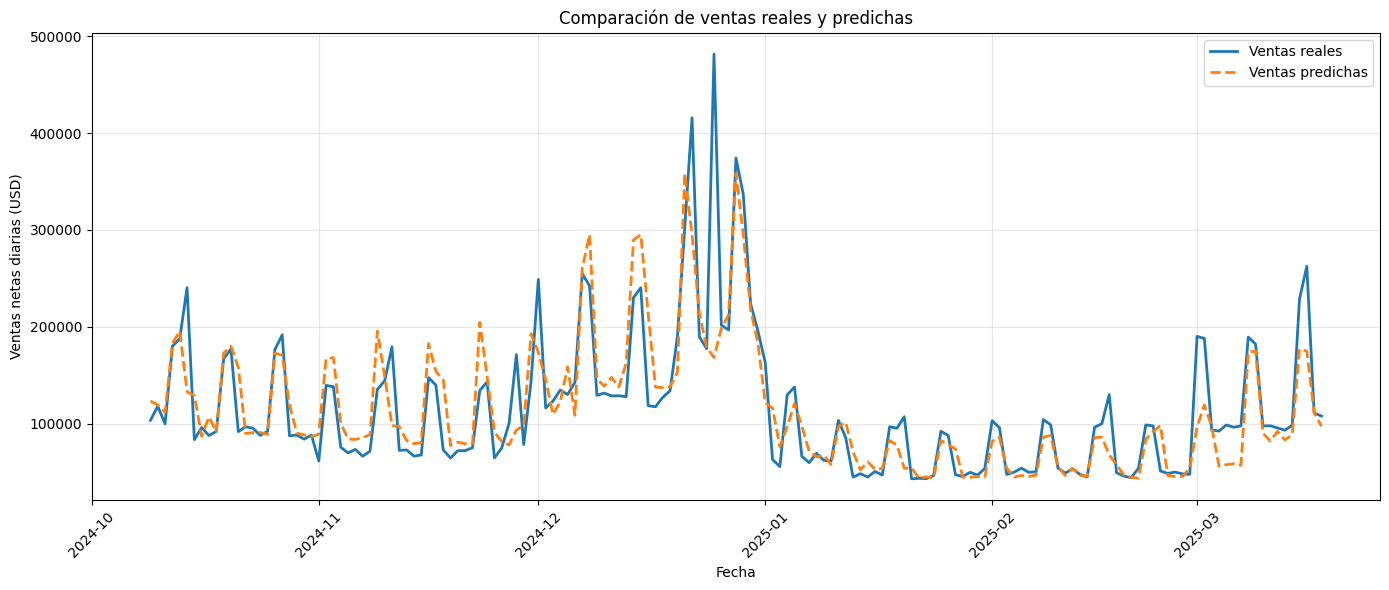

In [46]:
comparacion_predicciones = (
    predicciones
    .select("Dia", "Ventas_Diarias", "Prediccion")
    .orderBy("Dia")
    .toPandas()
)

plt.figure(figsize=(14, 6))

plt.plot(
    comparacion_predicciones["Dia"],
    comparacion_predicciones["Ventas_Diarias"],
    label="Ventas reales",
    linewidth=2
)

plt.plot(
    comparacion_predicciones["Dia"],
    comparacion_predicciones["Prediccion"],
    label="Ventas predichas",
    linewidth=2,
    linestyle="--"
)

plt.title("Comparación de ventas reales y predichas")
plt.xlabel("Fecha")
plt.ylabel("Ventas netas diarias (USD)")

plt.legend()
plt.grid(True, alpha=0.3)
plt.ticklabel_format(style="plain", axis="y")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [47]:
errores_modelo = (
    predicciones
    .withColumn(
        "Error_Absoluto",
        F.abs(
            F.col("Ventas_Diarias") -
            F.col("Prediccion")
        )
    )
    .orderBy(F.desc("Error_Absoluto"))
)

print("LOS 10 DIAS CON MAYORES ERRORES")

errores_modelo.select(
    F.col("Dia").alias("Fecha"),
    F.round("Ventas_Diarias", 2).alias("Ventas Reales"),
    F.round("Prediccion", 2).alias("Ventas Predichas"),
    F.round("Error_Absoluto", 2).alias("Error Absoluto")
).show(10, truncate=False)

LOS 10 DIAS CON MAYORES ERRORES
+----------+-------------+----------------+--------------+
|Fecha     |Ventas Reales|Ventas Predichas|Error Absoluto|
+----------+-------------+----------------+--------------+
|2024-12-25|481618.5     |168371.09       |313247.41     |
|2024-12-22|415892.25    |295128.95       |120763.3      |
|2024-10-14|240424.8     |132989.57       |107435.23     |
|2024-12-16|118656.0     |214142.75       |95486.75      |
|2025-03-01|190188.5     |96614.8         |93573.7       |
|2025-03-16|262518.36    |174928.12       |87590.24      |
|2024-11-11|179377.5     |97959.07        |81418.43      |
|2024-11-28|171288.1     |93471.11        |77816.99      |
|2024-12-01|248885.4     |173678.56       |75206.84      |
|2024-11-18|72947.5      |145300.35       |72352.85      |
+----------+-------------+----------------+--------------+
only showing top 10 rows


In [48]:
ventana_promedio = (
    Window.orderBy("Dia")
    .rowsBetween(-7, -1)
)

datos_modelo_v2 = (
    datos_modelo
    .withColumn(
        "Dia_Mes",
        F.dayofmonth("Dia")
    )
    .withColumn(
        "Fin_Semana",
        F.when(
            F.dayofweek("Dia").isin(1, 7),
            1
        ).otherwise(0)
    )
    .withColumn(
        "Promedio_7_Dias",
        F.avg("Ventas_Diarias").over(ventana_promedio)
    )
    .na.drop()
)

print("SEGUNDA VERSION DE LOS DATOS")

datos_modelo_v2.select(
    F.col("Dia").alias("Fecha"),
    F.col("Ventas_Diarias").alias("Ventas Reales"),
    F.col("Dia_Mes").alias("Día del Mes"),
    F.col("Fin_Semana").alias("Fin de Semana"),
    F.round("Promedio_7_Dias", 2).alias("Promedio de 7 Días")
).show(10, truncate=False)

print("TOTAL DE REGISTROS:", datos_modelo_v2.count())

SEGUNDA VERSION DE LOS DATOS
+----------+-------------+-----------+-------------+------------------+
|Fecha     |Ventas Reales|Día del Mes|Fin de Semana|Promedio de 7 Días|
+----------+-------------+-----------+-------------+------------------+
|2023-01-09|41175.0      |9          |0            |89422.8           |
|2023-01-10|39567.8      |10         |0            |65298.9           |
|2023-01-11|33375.8      |11         |0            |56721.87          |
|2023-01-12|36474.4      |12         |0            |50885.35          |
|2023-01-13|33334.9      |13         |0            |48003.16          |
|2023-01-14|68005.0      |14         |1            |45558.45          |
|2023-01-15|69263.2      |15         |1            |48765.1           |
|2023-01-16|86630.0      |16         |0            |45885.16          |
|2023-01-17|38010.3      |17         |0            |52378.73          |
|2023-01-18|34954.6      |18         |0            |52156.23          |
+----------+-------------+---------

In [49]:
entrenamiento_v2 = datos_modelo_v2.filter(
    F.col("Dia") <= "2024-10-08"
)

prueba_v2 = datos_modelo_v2.filter(
    F.col("Dia") >= "2024-10-09"
)

print("DIVISION DE DATOS - SEGUNDA VERSION")

print("Registros de entrenamiento:", entrenamiento_v2.count())
print("Registros de prueba:", prueba_v2.count())

print("PERIODO DE ENTRENAMIENTO")

entrenamiento_v2.agg(
    F.min("Dia").alias("Fecha de Inicio"),
    F.max("Dia").alias("Fecha de Termino")
).show(truncate=False)

print("PERIODO DE PRUEBA")

prueba_v2.agg(
    F.min("Dia").alias("Fecha de Inicio"),
    F.max("Dia").alias("Fecha de Termino")
).show(truncate=False)

DIVISION DE DATOS - SEGUNDA VERSION
Registros de entrenamiento: 639
Registros de prueba: 161
PERIODO DE ENTRENAMIENTO
+---------------+----------------+
|Fecha de Inicio|Fecha de Termino|
+---------------+----------------+
|2023-01-09     |2024-10-08      |
+---------------+----------------+

PERIODO DE PRUEBA
+---------------+----------------+
|Fecha de Inicio|Fecha de Termino|
+---------------+----------------+
|2024-10-09     |2025-03-18      |
+---------------+----------------+



In [50]:
variables_v2 = [
    "Ventas_Dia_Anterior",
    "Ventas_Hace_7_Dias",
    "Dia_Semana",
    "Mes",
    "Dia_Mes",
    "Fin_Semana",
    "Promedio_7_Dias"
]

preparador_v2 = VectorAssembler(
    inputCols=variables_v2,
    outputCol="features"
)

entrenamiento_ml_v2 = preparador_v2.transform(
    entrenamiento_v2
)

prueba_ml_v2 = preparador_v2.transform(
    prueba_v2
)

modelo_rf_v2 = RandomForestRegressor(
    featuresCol="features",
    labelCol="Ventas_Diarias",
    predictionCol="Prediccion",
    numTrees=50,
    maxDepth=5,
    seed=42
)

print("INICIANDO ENTRENAMIENTO DE RANDOM FOREST V2")

modelo_entrenado_v2 = modelo_rf_v2.fit(
    entrenamiento_ml_v2
)

print("SEGUNDA VERSION ENTRENADA CORRECTAMENTE")

INICIANDO ENTRENAMIENTO DE RANDOM FOREST V2
SEGUNDA VERSION ENTRENADA CORRECTAMENTE


In [51]:
predicciones_v2 = modelo_entrenado_v2.transform(
    prueba_ml_v2
)

mae_v2 = evaluador_mae.evaluate(predicciones_v2)
rmse_v2 = evaluador_rmse.evaluate(predicciones_v2)
r2_v2 = evaluador_r2.evaluate(predicciones_v2)

print("COMPARACION DE MODELOS RANDOM FOREST")

print("\nPRIMERA VERSION")
print(f"MAE: {mae:,.2f} USD")
print(f"RMSE: {rmse:,.2f} USD")
print(f"R2: {r2:.4f}")

print("\nSEGUNDA VERSION")
print(f"MAE: {mae_v2:,.2f} USD")
print(f"RMSE: {rmse_v2:,.2f} USD")
print(f"R2: {r2_v2:.4f}")

print("\nDIFERENCIA DE ERROR ABSOLUTO MEDIO")
print(f"{mae - mae_v2:,.2f} USD")

COMPARACION DE MODELOS RANDOM FOREST

PRIMERA VERSION
MAE: 23,035.82 USD
RMSE: 40,216.31 USD
R2: 0.6911

SEGUNDA VERSION
MAE: 21,997.79 USD
RMSE: 37,090.69 USD
R2: 0.7373

DIFERENCIA DE ERROR ABSOLUTO MEDIO
1,038.03 USD


In [52]:
ventana_14_dias = (
    Window.orderBy("Dia")
    .rowsBetween(-14, -1)
)

datos_modelo_v3 = (
    datos_modelo_v2
    .withColumn(
        "Ventas_Hace_14_Dias",
        F.lag("Ventas_Diarias", 14).over(
            Window.orderBy("Dia")
        )
    )
    .withColumn(
        "Promedio_14_Dias",
        F.avg("Ventas_Diarias").over(ventana_14_dias)
    )
    .withColumn(
        "Es_Diciembre",
        F.when(F.month("Dia") == 12, 1).otherwise(0)
    )
    .withColumn(
        "Es_Navidad",
        F.when(
            (F.month("Dia") == 12) &
            (F.dayofmonth("Dia") == 25),
            1
        ).otherwise(0)
    )
    .withColumn(
        "Es_Fin_De_Anio",
        F.when(
            (F.month("Dia") == 12) &
            (F.dayofmonth("Dia") == 31),
            1
        ).otherwise(0)
    )
    .na.drop()
)

print("TERCERA VERSION DE LOS DATOS")

datos_modelo_v3.select(
    F.col("Dia").alias("Fecha"),
    F.col("Ventas_Diarias").alias("Ventas Reales"),
    F.col("Ventas_Hace_14_Dias").alias("Ventas Hace 14 Dias"),
    F.round("Promedio_14_Dias", 2).alias("Promedio 14 Dias"),
    F.col("Es_Diciembre").alias("Diciembre"),
    F.col("Es_Navidad").alias("Navidad"),
    F.col("Es_Fin_De_Anio").alias("Fin de Año")
).show(15, truncate=False)

print("TOTAL DE REGISTROS V3:", datos_modelo_v3.count())

TERCERA VERSION DE LOS DATOS
+----------+-------------+-------------------+----------------+---------+-------+----------+
|Fecha     |Ventas Reales|Ventas Hace 14 Dias|Promedio 14 Dias|Diciembre|Navidad|Fin de Año|
+----------+-------------+-------------------+----------------+---------+-------+----------+
|2023-01-23|31951.8      |41175.0            |48606.0         |0        |0      |0         |
|2023-01-24|37468.5      |39567.8            |47947.2         |0        |0      |0         |
|2023-01-25|34811.3      |33375.8            |47797.25        |0        |0      |0         |
|2023-01-26|36649.0      |36474.4            |47899.79        |0        |0      |0         |
|2023-01-27|32742.4      |33334.9            |47912.26        |0        |0      |0         |
|2023-01-28|63261.5      |68005.0            |47869.94        |0        |0      |0         |
|2023-01-29|61507.5      |69263.2            |47531.11        |0        |0      |0         |
|2023-01-30|32577.7      |86630.0        

In [53]:
entrenamiento_v3 = datos_modelo_v3.filter(
    F.col("Dia") <= "2024-06-30"
)

validacion_v3 = datos_modelo_v3.filter(
    (F.col("Dia") >= "2024-07-01") &
    (F.col("Dia") <= "2024-10-08")
)

prueba_v3 = datos_modelo_v3.filter(
    F.col("Dia") >= "2024-10-09"
)

print("DIVISION DE DATOS - RANDOM FOREST V3")

print("Entrenamiento:", entrenamiento_v3.count())
print("Validación:", validacion_v3.count())
print("Prueba:", prueba_v3.count())

print("TOTAL DE REGISTROS:", (
    entrenamiento_v3.count()
    + validacion_v3.count()
    + prueba_v3.count()
))

DIVISION DE DATOS - RANDOM FOREST V3
Entrenamiento: 525
Validación: 100
Prueba: 161
TOTAL DE REGISTROS: 786


In [54]:
variables_v3 = [
    "Ventas_Dia_Anterior",
    "Ventas_Hace_7_Dias",
    "Dia_Semana",
    "Mes",
    "Dia_Mes",
    "Fin_Semana",
    "Promedio_7_Dias",
    "Ventas_Hace_14_Dias",
    "Promedio_14_Dias",
    "Es_Diciembre",
    "Es_Navidad",
    "Es_Fin_De_Anio"
]

preparador_v3 = VectorAssembler(
    inputCols=variables_v3,
    outputCol="features"
)

entrenamiento_ml_v3 = preparador_v3.transform(
    entrenamiento_v3
)

validacion_ml_v3 = preparador_v3.transform(
    validacion_v3
)

prueba_ml_v3 = preparador_v3.transform(
    prueba_v3
)

print("VARIABLES DE RANDOM FOREST V3 PREPARADAS")

print("Cantidad de variables:", len(variables_v3))
print("Registros de entrenamiento:", entrenamiento_ml_v3.count())
print("Registros de validación:", validacion_ml_v3.count())
print("Registros de prueba:", prueba_ml_v3.count())


VARIABLES DE RANDOM FOREST V3 PREPARADAS
Cantidad de variables: 12
Registros de entrenamiento: 525
Registros de validación: 100
Registros de prueba: 161


In [55]:
configuraciones = [
    (50, 5),
    (100, 7)
]

resultados_validacion = []
modelos_v3 = {}

for arboles, profundidad in configuraciones:

    print(
        f"Entrenando modelo con {arboles} árboles "
        f"y profundidad {profundidad}"
    )

    algoritmo = RandomForestRegressor(
        featuresCol="features",
        labelCol="Ventas_Diarias",
        predictionCol="Prediccion",
        numTrees=arboles,
        maxDepth=profundidad,
        seed=42
    )

    modelo = algoritmo.fit(entrenamiento_ml_v3)

    predicciones_val = modelo.transform(validacion_ml_v3)

    error_mae = evaluador_mae.evaluate(predicciones_val)
    error_rmse = evaluador_rmse.evaluate(predicciones_val)

    resultados_validacion.append(
        (arboles, profundidad, error_mae, error_rmse)
    )

    modelos_v3[(arboles, profundidad)] = modelo

print("RESULTADOS DE VALIDACION")

for arboles, profundidad, error_mae, error_rmse in resultados_validacion:
    print(
        f"Árboles: {arboles}, Profundidad: {profundidad}, "
        f"MAE: {error_mae:,.2f} USD, "
        f"RMSE: {error_rmse:,.2f} USD"
    )

Entrenando modelo con 50 árboles y profundidad 5
Entrenando modelo con 100 árboles y profundidad 7
RESULTADOS DE VALIDACION
Árboles: 50, Profundidad: 5, MAE: 16,052.93 USD, RMSE: 30,448.89 USD
Árboles: 100, Profundidad: 7, MAE: 14,707.43 USD, RMSE: 28,387.13 USD


In [56]:
entrenamiento_final_v3 = datos_modelo_v3.filter(
    F.col("Dia") <= "2024-10-08"
)

entrenamiento_final_ml_v3 = preparador_v3.transform(
    entrenamiento_final_v3
)

print("REGISTROS DE ENTRENAMIENTO FINAL:",
      entrenamiento_final_ml_v3.count())

modelo_rf_final_v3 = RandomForestRegressor(
    featuresCol="features",
    labelCol="Ventas_Diarias",
    predictionCol="Prediccion",
    numTrees=100,
    maxDepth=7,
    seed=42
)

print("INICIANDO ENTRENAMIENTO FINAL V3")

modelo_entrenado_final_v3 = modelo_rf_final_v3.fit(
    entrenamiento_final_ml_v3
)

print("MODELO FINAL V3 ENTRENADO CORRECTAMENTE")

REGISTROS DE ENTRENAMIENTO FINAL: 625
INICIANDO ENTRENAMIENTO FINAL V3
MODELO FINAL V3 ENTRENADO CORRECTAMENTE


In [57]:
predicciones_final_v3 = modelo_entrenado_final_v3.transform(
    prueba_ml_v3
)

mae_v3 = evaluador_mae.evaluate(predicciones_final_v3)
rmse_v3 = evaluador_rmse.evaluate(predicciones_final_v3)
r2_v3 = evaluador_r2.evaluate(predicciones_final_v3)

print("EVALUACION DE RANDOM FOREST V3")

print(f"MAE: {mae_v3:,.2f} USD")
print(f"RMSE: {rmse_v3:,.2f} USD")
print(f"R2: {r2_v3:.4f}")

print("\nCOMPARACION CON RANDOM FOREST V2")

print(f"MAE V2: {mae_v2:,.2f} USD")
print(f"MAE V3: {mae_v3:,.2f} USD")

print(f"RMSE V2: {rmse_v2:,.2f} USD")
print(f"RMSE V3: {rmse_v3:,.2f} USD")

print(f"R2 V2: {r2_v2:.4f}")
print(f"R2 V3: {r2_v3:.4f}")

EVALUACION DE RANDOM FOREST V3
MAE: 17,975.91 USD
RMSE: 31,355.83 USD
R2: 0.8122

COMPARACION CON RANDOM FOREST V2
MAE V2: 21,997.79 USD
MAE V3: 17,975.91 USD
RMSE V2: 37,090.69 USD
RMSE V3: 31,355.83 USD
R2 V2: 0.7373
R2 V3: 0.8122


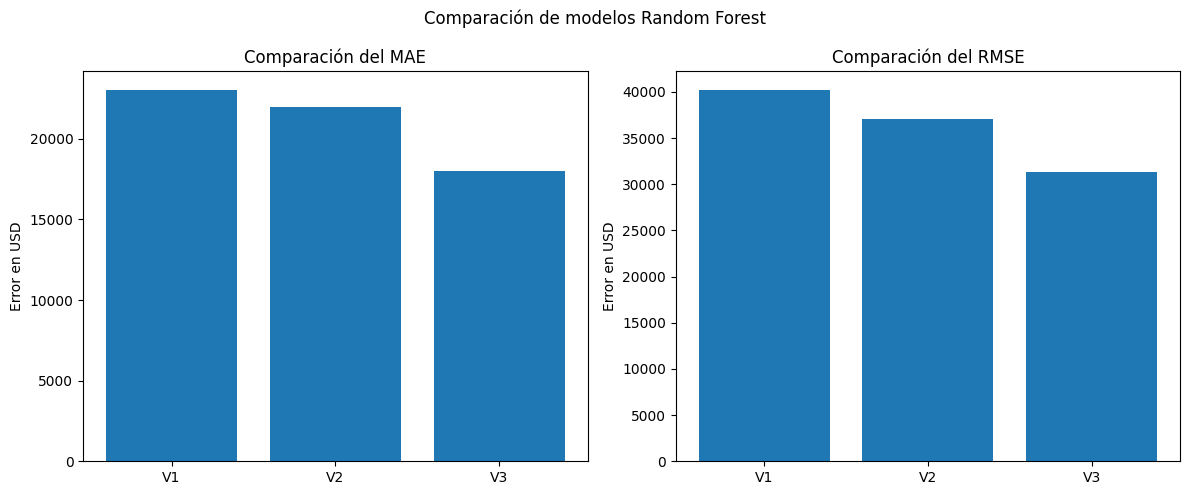

In [58]:
modelos_comparacion = ["V1", "V2", "V3"]
errores_mae = [mae, mae_v2, mae_v3]
errores_rmse = [rmse, rmse_v2, rmse_v3]

fig, ejes = plt.subplots(1, 2, figsize=(12, 5))

ejes[0].bar(modelos_comparacion, errores_mae)
ejes[0].set_title("Comparación del MAE")
ejes[0].set_ylabel("Error en USD")

ejes[1].bar(modelos_comparacion, errores_rmse)
ejes[1].set_title("Comparación del RMSE")
ejes[1].set_ylabel("Error en USD")

plt.suptitle("Comparación de modelos Random Forest")
plt.tight_layout()
plt.show()

In [59]:
ruta_modelo_v3 = "/content/modelo_random_forest_v3"

modelo_entrenado_final_v3.write().overwrite().save(
    ruta_modelo_v3
)

print("MODELO RANDOM FOREST V3 GUARDADO CORRECTAMENTE")

MODELO RANDOM FOREST V3 GUARDADO CORRECTAMENTE


In [60]:
ruta_modelo_drive_v3 = ruta + "/modelo_random_forest_v3"

shutil.copytree(
    ruta_modelo_v3,
    ruta_modelo_drive_v3,
    dirs_exist_ok=True
)

print("MODELO V3 RESPALDADO EN GOOGLE DRIVE")

MODELO V3 RESPALDADO EN GOOGLE DRIVE


In [64]:
from pyspark.ml.regression import RandomForestRegressionModel

modelo_recuperado_v3 = RandomForestRegressionModel.load(
    ruta_modelo_drive_v3
)

predicciones_recuperadas_v3 = modelo_recuperado_v3.transform(
    prueba_ml_v3
)

mae_recuperado_v3 = evaluador_mae.evaluate(
    predicciones_recuperadas_v3
)

print("VERIFICACION DEL MODELO GUARDADO")

print(f"MAE original: {mae_v3:,.2f} USD")
print(f"MAE recuperado: {mae_recuperado_v3:,.2f} USD")

if abs(mae_v3 - mae_recuperado_v3) < 0.01:
    print("MODELO RECUPERADO CORRECTAMENTE")
else:
    print("REVISAR RESULTADOS DEL MODELO")

Py4JJavaError: An error occurred while calling o9160.load.
: org.apache.spark.SparkException: Job aborted due to stage failure: Task 0 in stage 983.0 failed 1 times, most recent failure: Lost task 0.0 in stage 983.0 (TID 598) (f9acafb09a71 executor driver): java.lang.AssertionError: assertion failed: Decision Tree load failed.  Expected largest node ID to be 265, but found 132
	at scala.Predef$.assert(Predef.scala:279)
	at org.apache.spark.ml.tree.DecisionTreeModelReadWrite$.buildTreeFromNodes(treeModels.scala:439)
	at org.apache.spark.ml.tree.EnsembleModelReadWrite$.$anonfun$loadImpl$6(treeModels.scala:552)
	at scala.collection.Iterator$$anon$9.next(Iterator.scala:584)
	at scala.collection.Iterator$$anon$9.next(Iterator.scala:584)
	at org.apache.spark.util.random.SamplingUtils$.reservoirSampleAndCount(SamplingUtils.scala:42)
	at org.apache.spark.RangePartitioner$.$anonfun$sketch$1(Partitioner.scala:342)
	at org.apache.spark.RangePartitioner$.$anonfun$sketch$1$adapted(Partitioner.scala

In [65]:
ruta_modelo_local = "/content/modelo_recuperado_v3"

shutil.copytree(
    ruta_modelo_drive_v3,
    ruta_modelo_local,
    dirs_exist_ok=True
)

print("MODELO COPIADO AL ALMACENAMIENTO LOCAL")

print("Archivos encontrados:")
print(os.listdir(ruta_modelo_local))

MODELO COPIADO AL ALMACENAMIENTO LOCAL
Archivos encontrados:
['data', 'treesMetadata', 'metadata']


In [66]:
modelo_recuperado_v3 = RandomForestRegressionModel.load(
    ruta_modelo_local
)

print("MODELO RANDOM FOREST V3 CARGADO CORRECTAMENTE")


Py4JJavaError: An error occurred while calling o9163.load.
: org.apache.spark.SparkException: Job aborted due to stage failure: Task 0 in stage 991.0 failed 1 times, most recent failure: Lost task 0.0 in stage 991.0 (TID 611) (f9acafb09a71 executor driver): java.lang.AssertionError: assertion failed: Decision Tree load failed.  Expected largest node ID to be 265, but found 132
	at scala.Predef$.assert(Predef.scala:279)
	at org.apache.spark.ml.tree.DecisionTreeModelReadWrite$.buildTreeFromNodes(treeModels.scala:439)
	at org.apache.spark.ml.tree.EnsembleModelReadWrite$.$anonfun$loadImpl$6(treeModels.scala:552)
	at scala.collection.Iterator$$anon$9.next(Iterator.scala:584)
	at scala.collection.Iterator$$anon$9.next(Iterator.scala:584)
	at org.apache.spark.util.random.SamplingUtils$.reservoirSampleAndCount(SamplingUtils.scala:42)
	at org.apache.spark.RangePartitioner$.$anonfun$sketch$1(Partitioner.scala:342)
	at org.apache.spark.RangePartitioner$.$anonfun$sketch$1$adapted(Partitioner.scala

In [67]:
print("VERIFICACION DEL MODELO EN MEMORIA")

if "modelo_entrenado_final_v3" in globals():

    print("El modelo V3 existe en memoria")

    try:
        predicciones_memoria = modelo_entrenado_final_v3.transform(
            prueba_ml_v3
        )

        mae_memoria = evaluador_mae.evaluate(
            predicciones_memoria
        )

        print(f"MAE del modelo: {mae_memoria:,.2f} USD")
        print("MODELO EN MEMORIA FUNCIONANDO CORRECTAMENTE")

    except Exception as error:
        print("El modelo existe, pero produjo un error:")
        print(str(error)[:1000])

else:
    print("El modelo V3 no se encuentra en memoria")

VERIFICACION DEL MODELO EN MEMORIA
El modelo V3 existe en memoria
MAE del modelo: 17,975.91 USD
MODELO EN MEMORIA FUNCIONANDO CORRECTAMENTE


In [68]:
ruta_modelo_nuevo = "/content/modelo_random_forest_v3_recuperado"

modelo_entrenado_final_v3.write().save(
    ruta_modelo_nuevo
)

print("NUEVO RESPALDO DEL MODELO CREADO")

print("Archivos guardados:")
print(os.listdir(ruta_modelo_nuevo))

NUEVO RESPALDO DEL MODELO CREADO
Archivos guardados:
['data', 'treesMetadata', 'metadata']


In [69]:
modelo_verificacion = RandomForestRegressionModel.load(
    ruta_modelo_nuevo
)

predicciones_verificacion = modelo_verificacion.transform(
    prueba_ml_v3
)

mae_verificacion = evaluador_mae.evaluate(
    predicciones_verificacion
)

print("VERIFICACION DEL NUEVO RESPALDO")

print(f"MAE original: {mae_v3:,.2f} USD")
print(f"MAE recuperado: {mae_verificacion:,.2f} USD")

if abs(mae_v3 - mae_verificacion) < 0.01:
    print("NUEVO RESPALDO FUNCIONANDO CORRECTAMENTE")
else:
    print("REVISAR RESULTADOS")


VERIFICACION DEL NUEVO RESPALDO
MAE original: 17,975.91 USD
MAE recuperado: 17,975.91 USD
NUEVO RESPALDO FUNCIONANDO CORRECTAMENTE


In [70]:
ruta_modelo_drive_nuevo = (
    ruta + "/modelo_random_forest_v3_respaldo_final"
)

shutil.copytree(
    ruta_modelo_nuevo,
    ruta_modelo_drive_nuevo
)

print("NUEVO MODELO RESPALDADO EN GOOGLE DRIVE")

print("Archivos guardados:")
print(os.listdir(ruta_modelo_drive_nuevo))

NUEVO MODELO RESPALDADO EN GOOGLE DRIVE
Archivos guardados:
['data', 'treesMetadata', 'metadata']


In [71]:
ruta_verificacion_drive = "/content/verificacion_respaldo_final"

shutil.copytree(
    ruta_modelo_drive_nuevo,
    ruta_verificacion_drive
)

modelo_final_verificado = RandomForestRegressionModel.load(
    ruta_verificacion_drive
)

predicciones_finales_verificadas = (
    modelo_final_verificado.transform(prueba_ml_v3)
)

mae_final_verificado = evaluador_mae.evaluate(
    predicciones_finales_verificadas
)

print("VERIFICACION DEL RESPALDO DE GOOGLE DRIVE")

print(f"MAE original: {mae_v3:,.2f} USD")
print(f"MAE recuperado: {mae_final_verificado:,.2f} USD")

if abs(mae_v3 - mae_final_verificado) < 0.01:
    print("RESPALDO DE GOOGLE DRIVE VERIFICADO CORRECTAMENTE")
else:
    print("REVISAR RESULTADOS DEL RESPALDO")

VERIFICACION DEL RESPALDO DE GOOGLE DRIVE
MAE original: 17,975.91 USD
MAE recuperado: 17,975.91 USD
RESPALDO DE GOOGLE DRIVE VERIFICADO CORRECTAMENTE


In [72]:
!pip -q install psycopg2-binary

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.3/4.3 MB 15.4 MB/s eta 0:00:00


In [74]:
from google.colab import userdata
import psycopg2

conexion_url = userdata.get("SUPABASE_DB_URL")

conexion = psycopg2.connect(
    conexion_url,
    connect_timeout=15,
    sslmode="require"
)

cursor = conexion.cursor()

cursor.execute("SELECT current_database(), current_user;")

resultado = cursor.fetchone()

print("CONEXION CON SUPABASE EXITOSA")
print("Base de datos:", resultado[0])
print("Usuario conectado:", resultado[1])

cursor.close()
conexion.close()

CONEXION CON SUPABASE EXITOSA
Base de datos: postgres
Usuario conectado: postgres


In [75]:
ventas_mensuales_cloud = (
    datos_parquet
    .groupBy("Anio", "Mes", "Currency")
    .agg(
        F.round(
            F.sum("Line Total"), 2
        ).alias("Ventas_Netas")
    )
    .orderBy("Anio", "Mes", "Currency")
)

print("DATOS PREPARADOS PARA SUPABASE")

ventas_mensuales_cloud.select(
    F.col("Anio").alias("Año"),
    F.col("Mes"),
    F.col("Currency").alias("Moneda"),
    F.format_number(
        F.col("Ventas_Netas"), 2
    ).alias("Ventas Netas")
).show(12, truncate=False)

print("TOTAL DE REGISTROS:", ventas_mensuales_cloud.count())

DATOS PREPARADOS PARA SUPABASE
+----+---+------+-------------+
|Año |Mes|Moneda|Ventas Netas |
+----+---+------+-------------+
|2023|1  |CNY   |9,743,702.14 |
|2023|1  |EUR   |2,138,837.25 |
|2023|1  |GBP   |347,542.59   |
|2023|1  |USD   |1,671,839.80 |
|2023|2  |CNY   |8,253,426.70 |
|2023|2  |EUR   |1,529,303.95 |
|2023|2  |GBP   |317,651.34   |
|2023|2  |USD   |1,243,827.80 |
|2023|3  |CNY   |21,762,846.71|
|2023|3  |EUR   |4,581,510.73 |
|2023|3  |GBP   |812,978.31   |
|2023|3  |USD   |3,088,239.42 |
+----+---+------+-------------+
only showing top 12 rows
TOTAL DE REGISTROS: 108


In [77]:
registros = ventas_mensuales_cloud.collect()

datos_insertar = [
    (
        int(fila["Anio"]),
        int(fila["Mes"]),
        str(fila["Currency"]),
        Decimal(str(fila["Ventas_Netas"]))
    )
    for fila in registros
]

print("REGISTROS PREPARADOS:", len(datos_insertar))

conexion = psycopg2.connect(
    userdata.get("SUPABASE_DB_URL"),
    connect_timeout=15,
    sslmode="require"
)

try:
    with conexion:
        with conexion.cursor() as cursor:

            cursor.executemany(
                """
                INSERT INTO public.ventas_mensuales
                    (anio, mes, moneda, ventas_netas)
                VALUES (%s, %s, %s, %s)
                ON CONFLICT (anio, mes, moneda)
                DO UPDATE SET
                    ventas_netas = EXCLUDED.ventas_netas
                """,
                datos_insertar
            )

            cursor.execute(
                "SELECT COUNT(*) FROM public.ventas_mensuales"
            )

            total_guardados = cursor.fetchone()[0]

    print("DATOS ENVIADOS CORRECTAMENTE A SUPABASE")
    print("Registros preparados:", len(datos_insertar))
    print("Registros en PostgreSQL:", total_guardados)

except Exception as error:
    print("ERROR AL INSERTAR LOS DATOS")
    print(str(error)[:1000])

finally:
    conexion.close()

REGISTROS PREPARADOS: 108
DATOS ENVIADOS CORRECTAMENTE A SUPABASE
Registros preparados: 108
Registros en PostgreSQL: 108


In [78]:
conexion = psycopg2.connect(
    userdata.get("SUPABASE_DB_URL"),
    connect_timeout=15,
    sslmode="require"
)

try:
    with conexion:
        with conexion.cursor() as cursor:
            cursor.execute(
                """
                INSERT INTO public.resultados_modelo (
                    nombre_modelo,
                    algoritmo,
                    registros_entrenamiento,
                    registros_prueba,
                    cantidad_variables,
                    cantidad_arboles,
                    profundidad_maxima,
                    mae,
                    rmse,
                    r2
                )
                VALUES (%s, %s, %s, %s, %s, %s, %s, %s, %s, %s)
                ON CONFLICT (nombre_modelo)
                DO UPDATE SET
                    mae = EXCLUDED.mae,
                    rmse = EXCLUDED.rmse,
                    r2 = EXCLUDED.r2,
                    fecha_registro = NOW()
                """,
                (
                    "Random Forest V3",
                    "Random Forest Regression",
                    625,
                    161,
                    len(variables_v3),
                    100,
                    7,
                    Decimal(str(round(mae_v3, 2))),
                    Decimal(str(round(rmse_v3, 2))),
                    Decimal(str(round(r2_v3, 4)))
                )
            )

    print("RESULTADOS DEL MODELO GUARDADOS EN SUPABASE")

finally:
    conexion.close()

RESULTADOS DEL MODELO GUARDADOS EN SUPABASE
